In [1]:
# LAB EXPERIMENT 2
# Logistic Regression and Perceptron


import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
# 1. LOAD BREAST CANCER DATASET

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Dataset shape: (569, 30)
Number of samples: 569
Number of features: 30


In [3]:
# 2. TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
# 3. FEATURE SCALING

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [20]:
# 4. LOGISTIC REGRESSION FROM SCRATCH

class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, epochs=1000):

        self.learning_rate = learning_rate
        self.epochs = epochs

        self.weights = None
        self.bias = 0

        # Store loss after every epoch
        self.loss_history = []

    # Sigmoid Function

    def sigmoid(self, z):

        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    # Training using Gradient Descent
    
    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Initialize weights
        self.weights = np.zeros(n_features)

        self.bias = 0

        # Repeat for given number of epochs
        for epoch in range(self.epochs):
            
            # Step 1: Linear equation
            # z = XW + b

            z = np.dot(X, self.weights) + self.bias

            # Step 2: Sigmoid

            y_pred = self.sigmoid(z)
            
            # Step 3: Calculate Loss
            # Binary Cross Entropy
   
            epsilon = 1e-15

            loss = -np.mean(
                y * np.log(y_pred + epsilon)
                +
                (1 - y) * np.log(1 - y_pred + epsilon)
            )

            # Store loss for Gradient Descent graph
            self.loss_history.append(loss)

            # Step 4: Calculate gradients
         

            dw = (1 / n_samples) * np.dot(
                X.T,
                (y_pred - y)
            )

            db = (1 / n_samples) * np.sum(
                y_pred - y
            )

            # Step 5: Update weights and bias

            self.weights -= self.learning_rate * dw

            self.bias -= self.learning_rate * db

    # Predict Probability

    def predict_probability(self, X):

        z = np.dot(X, self.weights) + self.bias

        return self.sigmoid(z)

    # Predict Class


    def predict(self, X):

        probability = self.predict_probability(X)

        return (probability >= 0.5).astype(int)

In [21]:
# 5. TRAIN LOGISTIC REGRESSION
logistic_model = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=1000
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)


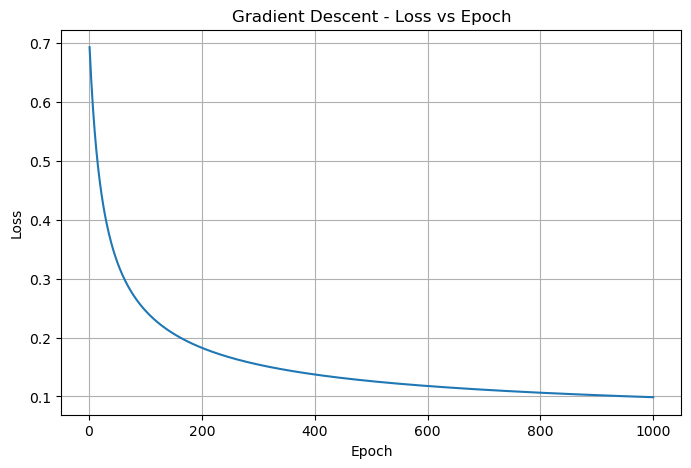

In [22]:
# 6. GRADIENT DESCENT GRAPH

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, logistic_model.epochs + 1),
    logistic_model.loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Gradient Descent - Loss vs Epoch")

plt.grid(True)

plt.show()

In [23]:
# 7. PERCEPTRON FROM SCRATCH

class Perceptron:

    def __init__(self, learning_rate=0.01, epochs=1000):

        self.learning_rate = learning_rate
        self.epochs = epochs

        self.weights = None
        self.bias = 0


    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)

        self.bias = 0

        # Convert 0,1 → -1,+1

        y_perceptron = np.where(
            y == 0,
            -1,
            1
        )


        for epoch in range(self.epochs):

            for i in range(n_samples):

                linear_output = (
                    np.dot(X[i], self.weights)
                    +
                    self.bias
                )


                # Check wrong prediction

                if y_perceptron[i] * linear_output <= 0:

                    # Update weights

                    self.weights += (
                        self.learning_rate
                        *
                        y_perceptron[i]
                        *
                        X[i]
                    )


                    # Update bias

                    self.bias += (
                        self.learning_rate
                        *
                        y_perceptron[i]
                    )


    def predict(self, X):

        linear_output = (
            np.dot(X, self.weights)
            +
            self.bias
        )

        return (linear_output >= 0).astype(int)

In [24]:
# 8. TRAIN PERCEPTRON
perceptron_model = Perceptron(
    learning_rate=0.01,
    epochs=1000
)

perceptron_model.fit(
    X_train,
    y_train
)

y_pred_perceptron = perceptron_model.predict(
    X_test
)

In [25]:
# 9. EVALUATION

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred
    )

    recall = recall_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred
    )


    print("\n================================")
    print(name)
    print("================================")

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)

    # Logistic Regression

evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)


# Perceptron

evaluate_model(
    "Perceptron",
    y_test,
    y_pred_perceptron
)


Logistic Regression
Accuracy : 0.9736842105263158
Precision: 0.9859154929577465
Recall   : 0.9722222222222222
F1-Score : 0.9790209790209791

Perceptron
Accuracy : 0.9385964912280702
Precision: 0.9710144927536232
Recall   : 0.9305555555555556
F1-Score : 0.950354609929078


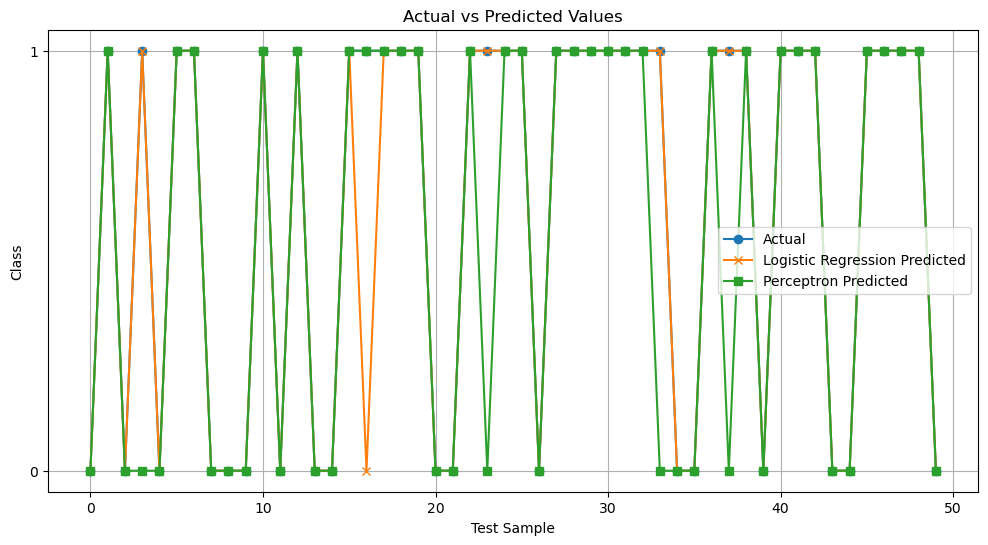

In [26]:
# 10. ACTUAL VS PREDICTED GRAPH

# Take first 50 test samples for easier visualization

n = 50

sample_index = np.arange(n)


plt.figure(figsize=(12, 6))

plt.plot(
    sample_index,
    y_test[:n],
    marker='o',
    label="Actual"
)

plt.plot(
    sample_index,
    y_pred_logistic[:n],
    marker='x',
    label="Logistic Regression Predicted"
)

plt.plot(
    sample_index,
    y_pred_perceptron[:n],
    marker='s',
    label="Perceptron Predicted"
)

plt.xlabel("Test Sample")

plt.ylabel("Class")

plt.title("Actual vs Predicted Values")

plt.yticks([0, 1])

plt.legend()

plt.grid(True)

plt.show()



In [27]:

# 11. DECISION BOUNDARY USING 2 FEATURES


feature1 = 0
feature2 = 1

X_2 = data.data[:, [feature1, feature2]]

y_2 = data.target


# Train-test split

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2,
    y_2,
    test_size=0.2,
    random_state=42,
    stratify=y_2
)


# Scale

scaler_2 = StandardScaler()

X2_train = scaler_2.fit_transform(X2_train)

X2_test = scaler_2.transform(X2_test)

In [28]:
# 12. TRAIN LOGISTIC REGRESSION WITH 2 FEATURES

logistic_2 = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=1000
)

logistic_2.fit(
    X2_train,
    y2_train
)



In [29]:
# 13. TRAIN PERCEPTRON WITH 2 FEATURES

perceptron_2 = Perceptron(
    learning_rate=0.01,
    epochs=1000
)

perceptron_2.fit(
    X2_train,
    y2_train
)


In [30]:
# 14. CREATE GRID


x_min = X2_train[:, 0].min() - 1
x_max = X2_train[:, 0].max() + 1

y_min = X2_train[:, 1].min() - 1
y_max = X2_train[:, 1].max() + 1


xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)


grid = np.c_[
    xx.ravel(),
    yy.ravel()
]


# Predictions

Z_logistic = logistic_2.predict(grid)

Z_perceptron = perceptron_2.predict(grid)


Z_logistic = Z_logistic.reshape(
    xx.shape
)

Z_perceptron = Z_perceptron.reshape(
    xx.shape
)



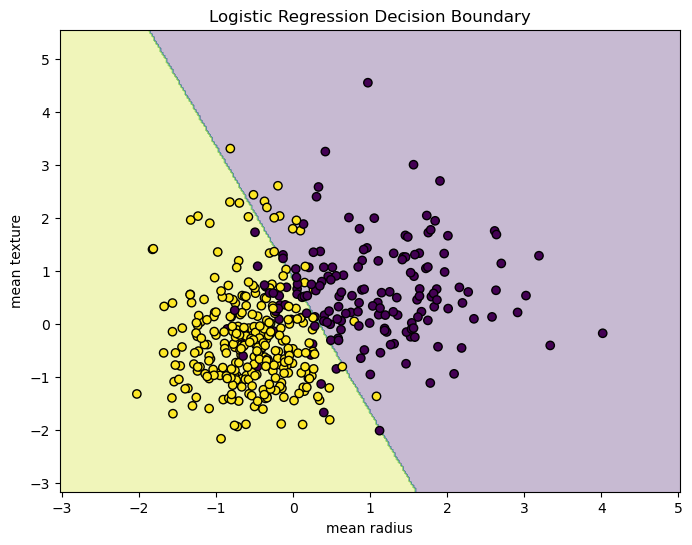

In [31]:
# 15. LOGISTIC REGRESSION DECISION BOUNDARY


plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z_logistic,
    alpha=0.3
)

plt.scatter(
    X2_train[:, 0],
    X2_train[:, 1],
    c=y2_train,
    edgecolors='black'
)

plt.xlabel(
    data.feature_names[feature1]
)

plt.ylabel(
    data.feature_names[feature2]
)

plt.title(
    "Logistic Regression Decision Boundary"
)

plt.show()



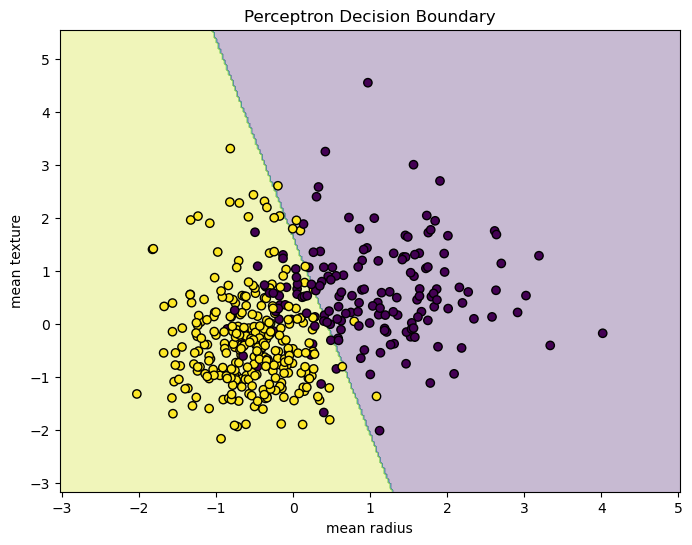

In [32]:
# 16. PERCEPTRON DECISION BOUNDARY

plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z_perceptron,
    alpha=0.3
)

plt.scatter(
    X2_train[:, 0],
    X2_train[:, 1],
    c=y2_train,
    edgecolors='black'
)

plt.xlabel(
    data.feature_names[feature1]
)

plt.ylabel(
    data.feature_names[feature2]
)

plt.title(
    "Perceptron Decision Boundary"
)

plt.show()